In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

#Membuat DataFrame dari data yang diberikan
data = {
    'Partisipan': [50, 40, 60, 55, 45, 65, 70, 75, 80, 90],
    'PMakan': [20, 25, 30, 35, 40, 50, 55, 60, 65, 70],
    'PTranspor':[60, 55, 65, 70, 62, 75, 80, 85, 90, 95],
    'BB': [60, 55, 65, 70, 62, 75, 80, 85, 90, 95]}

df = pd.DataFrame(data)

#Memisahkan variabel independen dan dependen
x = df[['PMakan', 'PTranspor']]
y = df['BB']

x = sm.add_constant(x)

model = sm.OLS(y, x)  #Membangun model regresi
results = model.fit()

print(results.summary()) #Menampilkan hasil

                            OLS Regression Results                            
Dep. Variable:                     BB   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 3.359e+29
Date:                Thu, 24 Sep 2026   Prob (F-statistic):          3.65e-102
Time:                        07:27:12   Log-Likelihood:                 293.94
No. Observations:                  10   AIC:                            -581.9
Df Residuals:                       7   BIC:                            -581.0
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.137e-13   1.76e-13      0.647      0.5

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import plotly.graph_objects as go
data = "https://github.com/Alam-A99/DATAAKSI/blob/main/dataset_fiskal_97_hipoFull.csv"

data = {
    "Tahun": (2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024),
    "DBH_Pajak": (42.73, 71.45, 65.63, 58.74, 58.06, 76.35, 71.69, 83.69, 85.2, 58.26, 122.67),
    "DBH_SDA": (22.28,  53.5, 31.36, 40.3, 46.22, 24.48, 34.13, 55.68, 90.92, 81.0, 88.3),
    "DBH_Lainnya": (37.78, 43.11, 26.94, 41.38, 34.61, 36.86, 33.0, 46.3, 59.05, 31.45, 37.36),
    "Pengangguran": (3.6, 3.18, 8.17, 6.32, 9, 9.59,  3.16, 9.93, 8.79, 5.05, 3.82)}

df = pd.DataFrame(data)

#Variabel independen
x = df(( "DBH_Pajak", "DBH_SDA"))

#Variabel dependen
y = df("Pengangguran")

#Menambahkan Intercept
X_model = sm.add_constant(x)

#Estimasi Model OLS
model =  sm. OLS(y, X_model)
results = model.fit()

#Menampilkan Ringkasan Hasil Regresi
print("\n")
print("=" * 70)
print("HASIL REGRESI LINEAR BERGANDA")
print("=" * 70)
print(results.summary())

#Mengambil Koefisien Regresi
intercept = results.params["const"]
coef_pajak = results.params["DBH_Pajak"]
coef_sda = results.params[ "DBH_SDA"]
coef_lainnya = results.params["DBH_Lainnya"]

r_squared = results.rsquared
adjusted_r_squared = results.rsquared_adj

#Membuat Persamaan Regresi
persamaan = (
    f"Ŷ = {intercept:.3f}"
    f" + ({coef_pajak:.3f}) X1"
    f" + ({coef_sda:.3f}) X2"
    f" + ({coef_lainnya:.3f}) X3")

print("\n")
print("=" * 70)
print("PERSAMAAN REGRESI")
print("=" * 70)
print(persamaan)

print(f"\nR2 = {r_squared:.4f}")
print(f"Adjusted R2 = {adjusted_r_squared:.4f}")

#Menghitug Nilai Prediksi
df["Prediksi"] = results.predict(X_model)
print("\n")
print("=" * 70)
print("DATA AKTUAL & PREDIKSI")
print("=" * 70)

print(
    df[[ "Tahun", "DBH_Pajak", "DBH_SDA", "DBH_Lainnya", "Pengangguran",
      ]].round(2))

#Membuat Grid Untuk Bidang Regresi
x1 = np.linspace(
    df["DBH_Pajak"].min(),
    df["DBH_Pajak"].max(),
    40)
x2 = np.linspace(
    df["DBH_SDA"].min(),
    df["DBH_SDA"].max(),
    40)

X1, X2 = np.meshgrid(x1, x2)

#MENGHITUNG NILAI Y PADA BIDANG REGRESI
Y = ( intercept + coef_pajak * X1 + coef_sda * X2)

#MEMBUAT FIGURE 3D
fig = go.Figure()

#MENAMPILKAN DATA AKTUAL
fig.add_trace(
go.Scatter3d(
    x=df["DBH_Pajak"],
    y=df["DBH_SDA"],
    z=df["Pengangguran"],
    mode="markers",
    marker=dict(
        size=7,
        color="red",
        opacity=0.9
        ),
name="Data Aktual",
text=[
    f"Partisipan {p}"
    for p in df["Partisipan"]
    ],
hovertemplate=(
    "<b>%{text}</b><br>"
    "DBH_Pajak: %{x}<br>"
    "DBH_SDA: %{y}<br>"
    "Pengangguran: %{z}"
    "<extra></extra>"
    )))

#MENAMPILKAN BIDANG REGRESI
fig.add_trace(
    go.Surface(
        x=X1, y=X2, z=Y,
        opacity=0.60,
        colorscale="Viridis",
        name="Regression Plane",
        hovertemplate=(
            "DBH_Pajak: %{x:.2f}<br>"
            "DBH_SDA: %{y:.2f}<br>"
            "Prediksi Y: %{z:.2f}"
            "<extra></extra>")))

#MENGATUR TAMPILAN GRAFIK
fig.update_layout(
    title={
        "text": (
            "REGRESI LINEAR BERGANDA 3D"
            "<br>"
            f"<sup>{persamaan} | "
            f"R2 = {r_squared:.3f}</sup>" ), "x": 0.5 },
scene={
    "xaxis": {"title": "Pengeluaran Makanan (X1)" },
    "yaxis": {"title": "Pengeluaran Transportasi (X2)" },
    "zaxis": { "title": "Berat Badan (Y)" } },
width=1000,
height=750,
margin={
    "l": 0, "r": 0, "b": 0, "t": 100 },
legend={ "x": 0.02, "y": 0.98 })

# 16. MENAMPILKAN GRAFIK
fig.show()

TypeError: 'DataFrame' object is not callable

In [ ]:
import numpy as np
from scipy import stats
data = np.array([167, 184, 192, 198, 200, 202, 210, 211, 212, 215, 216, 217,])

# Perform normality test
result = stats.normaltest(data)

# Extract test statistics and p-value
test_statistic = result.statistic
p_value = result.pvalue

# Print the results
print("Test Statistic:", test_statistic)
print("p-value:", p_value)

Test Statistic: 5.0328669271302635
p-value: 0.08074708120787746


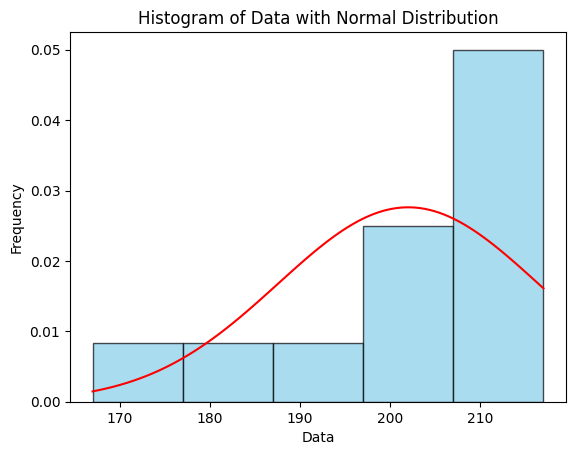

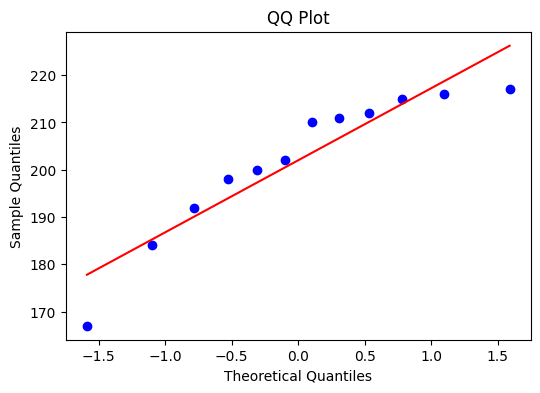

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
data = np.array([167, 184, 192, 198, 200, 202, 210, 211, 212, 215, 216, 217,])

# Plot histogram
plt.hist(data, bins='auto', density=True, alpha=0.7, color='skyblue', edgecolor='black')

# Plot kurva distribusi normal
mu, std = np.mean(data), np.std(data)
x = np.linspace(np.min(data), np.max(data), 100)
y = stats.norm.pdf(x, mu, std)
plt.plot(x, y, color='red')

# Set plot title and labels
plt.title('Histogram of Data with Normal Distribution')
plt.xlabel('Data')
plt.ylabel('Frequency')

# Show the plot
plt.show()

# QQ plot
plt.figure(figsize=(6, 4))
stats.probplot(data, dist="norm", plot=plt)

# Set plot title and labels
plt.title('QQ Plot')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Sample Quantiles')

# Show the plot
plt.show()

# sumber data : https://www.statext.com/practice/NormalityTest02.php

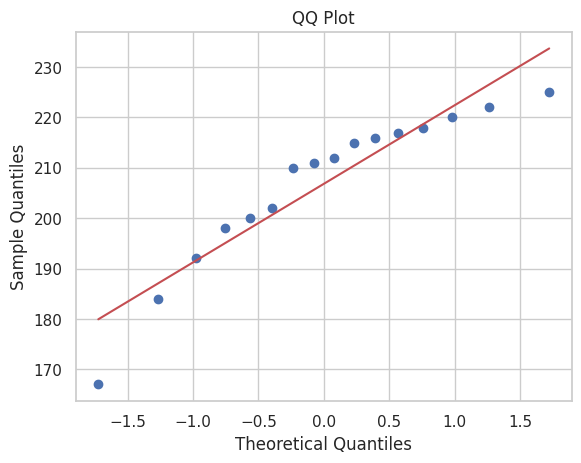

In [ ]:
# Python untuk visualisasi normalitas data menggunakan QQ plot
import numpy as np
import seaborn as sns
import scipy.stats as stats

data = np.array([167, 184, 192, 198, 200, 202, 210, 211, 212, 215, 216, 217, 218, 220, 222, 225])

# Generate QQ plot
sns.set(style="whitegrid")
stats.probplot(data, dist="norm", plot=sns.mpl.pyplot)

# Set plot title and labels
sns.mpl.pyplot.title('QQ Plot')
sns.mpl.pyplot.xlabel('Theoretical Quantiles')
sns.mpl.pyplot.ylabel('Sample Quantiles')

# Show the plot
sns.mpl.pyplot.show()

In [ ]:
import numpy as np
from scipy import stats
data = np.array([167, 184, 192, 198, 200, 202, 210, 211, 212, 215, 216, 217, 218, 219, 220, 222, 225])

# Kolmogorov-Smirnov Test
ks_statistic, ks_pvalue = stats.kstest(data, 'norm')
print("Kolmogorov-Smirnov Test:")
print("Test Statistic:", ks_statistic)
print("p-value:", ks_pvalue)

# Shapiro-Wilk Test
sw_statistic, sw_pvalue = stats.shapiro(data)
print("\nShapiro-Wilk Test:")
print("Test Statistic:", sw_statistic)
print("p-value:", sw_pvalue)

# Jarque-Bera Test
jb_statistic, jb_pvalue = stats.jarque_bera(data)
print("\nJarque-Bera Test:")
print("Test Statistic:", jb_statistic)
print("p-value:", jb_pvalue)

Kolmogorov-Smirnov Test:
Test Statistic: 1.0
p-value: 0.0

Shapiro-Wilk Test:
Test Statistic: 0.8748451215552352
p-value: 0.026257430916122905

Jarque-Bera Test:
Test Statistic: 4.915918435578957
p-value: 0.08560948312590012


UJI NORMALITAS

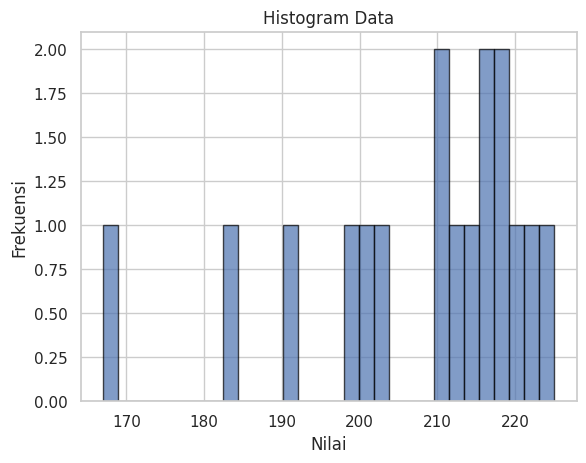

In [ ]:
# Uji normalitas
import numpy as np
import matplotlib.pyplot as plt

# Generate random data
np.random.seed(0)
tahun = np.arange(1, 11) # Variabel independen tahun
var1 = np.random.normal(0, 1, 10) # Variabel independen 1
#var2 = np.random.normal(0, 1, 10) # Variabel independen 2
#nilai_y = 2 * variabel1 + 3 * variabel2 + np.random.normal(0, 1, 10) # Variabel

# Plot histogram
plt.hist(data, bins=30, edgecolor='black', alpha=0.7)
plt.xlabel('Nilai')
plt.ylabel('Frekuensi')
plt.title('Histogram Data')
plt.grid(True)

plt.show()

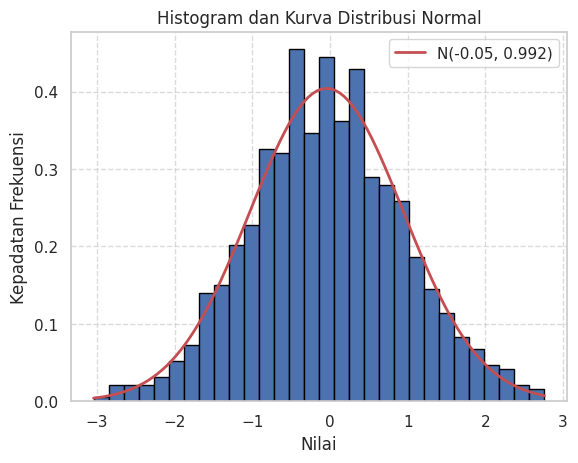

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Generate random data
np.random.seed(0)
tahun = np.arange(1, 11)
var1 = np.random.normal(0, 1, 1000) # data lebih banyak

# Hitung mean dan standar deviasi
mu, sigma = np.mean(var1), np.std(var1)

# Plot histogram
count, bins, ignored = plt.hist(var1, bins=30, density=True, edgecolor='black')

# Plot kurva distribusi normal
x = np.linspace(min(bins), max(bins), 100)
pdf = norm.pdf(x, mu, sigma) # fungsi kepadatan probabilitas normal
plt.plot(x, pdf, 'r-', linewidth=2, label=f'N({mu:.2f}, {sigma:.2f}2)')

# Tambahkan label dan grid
plt.xlabel('Nilai')
plt.ylabel('Kepadatan Frekuensi')
plt.title('Histogram dan Kurva Distribusi Normal')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

In [ ]:
import scipy.stats as stats

#Uji normalitas data koding di atas
_, p_value = stats.shapiro(var1)

#Cetak hasil uji normalitas
alpha = 0.05 #Tingkat signifikansi
if p_value > alpha:
  print("Data terdistribusi normal")
else:
  print("Data tidak terdistribusi nprmal")

Data terdistribusi normal


UJI ASUMSI KLASIK

Koefisien Regresi:
Beta0: 0.19150439774016692
Beta1: 1.9668368099981575
Beta2: 3.057085207213302


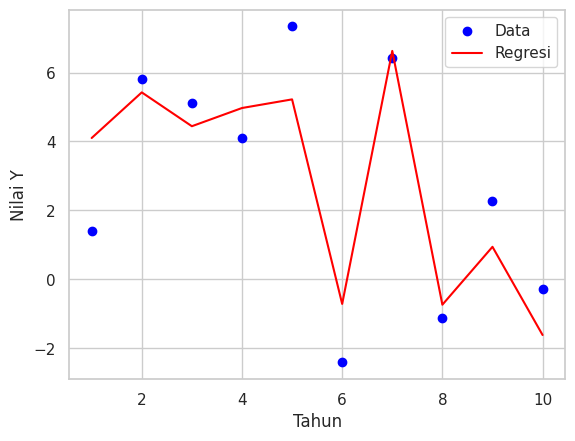

In [ ]:
#Regresi uji asumsi klasik
import numpy as np
import matplotlib.pyplot as plt

#Generate random data
np.random.seed(0)
tahun = np.arange(1, 11) #Variabel independen tahun
var1 = np.random.normal(0, 1, 10) #Variabel independen 1
var2 = np.random.normal(0, 1, 10) #Variabel independen 2
nilai_y = 2 * var1 + 3 * var2 + np.random.normal(0, 1, 10)

# Perform linear regression
X = np.column_stack((var1, var2)) # Matrix X dengan variabel independen
X = np.column_stack((np.ones(len(tahun)), X)) # Tambahkan kolom
beta = np.linalg.inv(X.T @ X) @ X.T @ nilai_y # Hitung parameter beta

print("Koefisien Regresi:")
for i in range(len(beta)):
  print(f"Beta{i}: {beta[i]}")

# Plotting data dan regresi
fig, ax = plt.subplots()
ax.scatter(tahun, nilai_y, color='blue', label='Data')
ax.plot(tahun, X @ beta, color='red', label='Regresi')
ax.set_xlabel('Tahun')
ax.set_ylabel('Nilai Y')
ax.legend()

plt.show()

UJI AUTOKORELASI

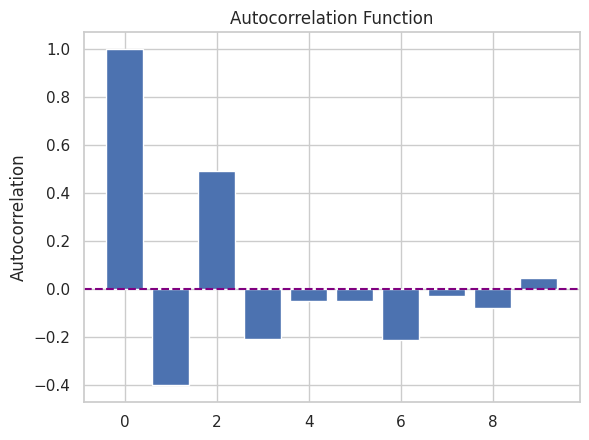

In [ ]:
#Uji Autokorelasi
import statsmodels.api as sm
import matplotlib.pyplot as plt

#Menghitung ACF
acf = sm.tsa.acf(nilai_y)

#Plot ACF
fig, ax = plt.subplots()
ax.bar(range(len(acf)), acf)
ax.axhline(y=0, color='purple', linestyle='--')
ax.set_ylabel('Autocorrelation')
ax.set_title('Autocorrelation Function')
plt.show()

HETEROSKEDASTISITAS: Uji White

In [ ]:

#HETEROSKEDASTISITAS: Uji White

import statsmodels.api as sm
from statsmodels.compat import lzip
from statsmodels.stats.diagnostic import het_white

#Fit model regresi
X = sm.add_constant(np.column_stack((var1, var2)))
model = sm.OLS(nilai_y, X).fit()

# Hitung heteroskedastisitas
_, p_value, _, _ = het_white(model.resid, X)

# Cetak hasil uji heteroskedastisitas
alpha = 0.05 # Tingkat signifikansi
if p_value > alpha:
  print("Tidak ada bukti heteroskedastisitas")
else:
  print("Ada bukti heteroskedastisitas")

Tidak ada bukti heteroskedastisitas


MULTIKOLONIERITAS

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

#1.Buat data contoh dengan multikolinearitas
np.random.seed(42)
n = 100

#Variabel independen
X1 = np.random.rand(n) * 10
#X2 sangat berkorelasi dengan X1 (multikolinear)
X2 = 2 * X1 + np.random.normal(0, 1, n)
X3 = np.random.rand(n) * 10

#Variabel dependen (misalnya model regresi)
Y = 3 + 2*X1 + 1.5*X2 + 0.5*X3 + np.random.normal(0, 2, n)

# 2. Gabungkan menjadi DataFrame
df = pd.DataFrame({'Y': Y, 'X1': X1, 'X2': X2, 'X3': X3})

# 3. Hitung Variance Inflation Factor (VIF)
X = sm.add_constant(df[['X1', 'X2', 'X3']])
vif_data = pd.DataFrame()
vif_data["Variable"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.s)]

#4. Tampilkan hasil
print(vif_data)

AttributeError: 'DataFrame' object has no attribute 's'